### Defições Gerais

In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:150% !important; }</style>"))
import warnings
warnings.simplefilter('ignore')

import pandas as pd
import matplotlib.pyplot as plot
import matplotlib.dates as mdates
import seaborn as sns
from plotly.offline import plot as plt
import plotly.graph_objs as go
import plotly.io as pio
import time
from datetime import datetime, timedelta, date
import teradata
import  businessdays as bzd



start = time.time() 
system = "TERADBAWS.sicredi.net"
user = "P_USR_DL_GESTAO_RECURSOS"
passw = "JAW0b71329aadade35365afc6X"
udaExec = teradata.UdaExec (appName="TESTE", version="1.0", logConsole=False)
session = udaExec.connect(method="odbc", system=system,
        username=user, password=passw, Authentication="TDNEGO");


select_feriados = "Select DT from dl_Gestao_recursos.bas_cad_fer where tipo in ('3','2')"
feriados = pd.read_sql(select_feriados, session)
cal = bzd.Calendar(holidays=feriados.DT,weekdays=['Sunday','Saturday'])

### Definições de datas e lista de flies

In [2]:
data_inicial = cal.offset(datetime.now(),-180  )###DATA PADRÃO D-180
data_inicial = data_inicial.strftime('%Y-%m-%d') ###DATA PADRÃO D-180

data_final = cal.offset(datetime.now(),-1)###DATA PADRÃO D-1
data_final = data_final.strftime('%Y-%m-%d') ###DATA PADRÃO D-1

#data_inicial='2023-01-01' #Caso queria definir manualmente
#data_final='2023-07-25'


lista_reduzida =  ['F25F26F27','F27F29F31','F29F31F33','F26F27F28','F27N27F28','F28N28F29']

lista_fly = ['N24V24F25',
'V24F25J25',
'F25J25N25',
'F25N25V25',
'F25N25F26',
'F25N25N26',
'J25N25V25',
'N25V25F26',
'N25F26N26',
'V25F26J26',
'N25N26N27',
'F26N26F27',
'F26J26N26',
'N26V26F26',
'N26N27F28',
'N26F27N27',
'F27N27F28',
'N26N27N28',
'F27N27N28',
'F28N28F29',
'N27F28N28',
'F25F26F27',
'F25F27F28',
'F25F27F29',
'F25F29F33',
'F26F27F28',
'F26F28F30',
'F27F28F29',
'F27F28F30',
'F27F29F31',
'F27F29F30',
'F27F30F33',
'F27F31F33',
'F28F29F30',
'F28F30F31',
'F28F30F32',
'F28F31F33',
'F29F30F31',
'F29F31F33',
'F31F33F35',
'F30F31F32',
'F30F31F33',
'F31F32F33']

### DEFINE FUNÇÃO GRAFICO DE FLYS

In [3]:

def FLY(lista_fly, dt_inicial = (date.today()+ timedelta(days=-180)).strftime('%d/%m/%Y'), dt_final = cal.offset(datetime.now(),-1).strftime('%d/%m/%Y'), graf_resultado = False):
    
    lista_string = "','".join(map(str,lista_fly))
    data_inicial = datetime.strptime(dt_inicial, "%d/%m/%Y").date()
    data_final = datetime.strptime(dt_final, "%d/%m/%Y").date()
    dt_final_sql = data_final.strftime('%Y-%m-%d')
    dt_inicial_sql = data_inicial.strftime('%Y-%m-%d')

        
    Select = f"""
     SELECT DISTINCT MDL.DT
    , MDL.FLY
    , MDL.TAXA

    , RES.CD_ESTRATEGIA
    , MDL.MEDIA_6M
    , MDL.LIM_SUP_6M
    , MDL.LIM_INF_6M
    , MDL.OPE_6M

    , MDL.FWD_AB
    , MDL.SPREAD_AB
    , MDL.FWD_AB_MODELO
    , MDL.SPREAD_AB_MODELO
    , MDL.FLY_ABC_MODELO

    , MDL.LIM_SUP_6M_MDL
    , MDL.LIM_INF_6M_MDL
    , MDL.FLY_GENERICA
    , MDL.DIV01_FLY

    , POS.TAXA_POS
    , POS.TAXA_COMPRA
    , POS.TAXA_VENDA
    , POS.QTDE_C
    , MDL.DIV01_FLY*POS.QTDE_C/MDL.QTDE_C AS DIV01_POS
    , POS.RESULTADO
    , ROUND(SUM(RES.RESULTADO) OVER (PARTITION BY RES.CD_ESTRATEGIA, POS.FLY ORDER BY POS.DT ROWS BETWEEN 260 PRECEDING AND CURRENT ROW),2) AS RESULTADO_ACUMULADO
    , ((IDX.VALOR/3000+1)**252.000000-1)*100 AS CDI

    FROM
    DL_GESTAO_RECURSOS.VW_MOD_FLY MDL
    LEFT JOIN 

    (SELECT DT, CD_ESTRATEGIA, FLY, AVG(TAXA_POS) AS TAXA_POS, SUM(QTDE_C) AS QTDE_C,AVG(TAXA_COMPRA) AS TAXA_COMPRA, AVG(TAXA_VENDA) AS TAXA_VENDA, SUM(RESULTADO) AS RESULTADO  
    FROM DL_GESTAO_RECURSOS.VW_fly_pos
    WHERE CD_ESTRATEGIA <> 'RF_FLY_26'
    GROUP BY 
    DT, CD_ESTRATEGIA, FLY) 
    POS ON POS.DT = MDL.DT AND POS.FLY = MDL.FLY
    LEFT JOIN
    (SELECT DT, CD_ESTRATEGIA, SUM(VL_RESULTADO) AS RESULTADO FROM DL_GESTAO_RECURSOS.FU_RESULTADO
        WHERE CD_ESTRATEGIA <> 'RF_FLY_26'
    GROUP BY CD_ESTRATEGIA, DT
    ) RES ON RES.DT = MDL.DT AND RES.CD_ESTRATEGIA = POS.CD_ESTRATEGIA
    LEFT JOIN DL_GESTAO_RECURSOS.IDX_INDEX IDX ON IDX.DATA = MDL.DT AND IDX.CODINDEX = 'CDI'
    WHERE MDL.DT between '{data_inicial}' and '{data_final}'
    AND MDL.FLY IN ('{lista_string}')
    """


    fly_df = pd.read_sql(Select, session) 
    fly_df.DT = pd.to_datetime(fly_df.DT, format='%Y-%m-%d')
    for x in lista_fly:   
        fly_grafico = fly_df[fly_df.FLY == x] 
        fly_grafico = fly_grafico.sort_values(by=['DT'])
        fly_grafico = fly_grafico.reset_index() 
        pd.set_option('mode.chained_assignment', None)

        TAXA = go.Scatter(x = fly_grafico.DT,y = fly_grafico['TAXA']*10000,mode = 'lines', name = 'Taxa', line = {'color': 'dodgerblue', 'width':1.5})
        TAXA_POS = go.Scatter(x = fly_grafico.DT,y = fly_grafico['TAXA_POS']*10000,mode = 'lines', name = 'Taxa_Pos', line = {'color': 'blue', 'width':1.5})
        TAXA_COMPRA = go.Scatter(x = fly_grafico.DT,y = fly_grafico['TAXA_COMPRA']*10000,mode = 'markers', name = 'Taxa_Compra', marker = {'color': 'green'})
        TAXA_VENDA = go.Scatter(x = fly_grafico.DT,y = fly_grafico['TAXA_VENDA']*10000,mode = 'markers', name = 'Taxa_venda', marker = {'color': 'tomato'})

        MEDIA = go.Scatter(x = fly_grafico.DT,y = fly_grafico['MEDIA_6M']*10000,mode = 'lines', name = 'Média', line = {'color': 'goldenrod', 'width':0.5,'dash':'dash'})
        LIM_SUP = go.Scatter(x = fly_grafico.DT,y = fly_grafico['LIM_INF_6M']*10000,mode = 'lines', name = 'Lim Superior', line = {'color': 'goldenrod', 'width':0.7})
        LIM_INF = go.Scatter(x = fly_grafico.DT,y = fly_grafico['LIM_SUP_6M']*10000,mode = 'lines', name = 'Lim Inferior', line = {'color': 'goldenrod', 'width':0.7})
        MODELO = go.Scatter(x = fly_grafico.DT,y = fly_grafico['FLY_ABC_MODELO']*10000,mode = 'lines', name = 'Taxa Modelo', line = {'color': 'darkviolet', 'width':0.5,'dash':'dash'})
        LIM_SUP_MDL = go.Scatter(x = fly_grafico.DT, y = fly_grafico['LIM_INF_6M_MDL']*10000,mode = 'lines', name = 'Lim Sup Modelo', line = {'color': 'darkviolet', 'width':0.7})
        LIM_INF_MDL = go.Scatter(x = fly_grafico.DT, y = fly_grafico['LIM_SUP_6M_MDL']*10000,mode = 'lines', name = 'Lim Inf Modelo', line = {'color': 'darkviolet', 'width':0.7})

        data = [TAXA, MEDIA,TAXA_POS,TAXA_COMPRA,TAXA_VENDA, LIM_SUP,LIM_INF,MODELO,LIM_SUP_MDL, LIM_INF_MDL]
        layout = dict(title = x,
                       xaxis = dict(title = 'Data')
                       ,yaxis = dict(title = 'Taxa')
                       #xaxis_rangeslider_visible=True
                       )

        fig = dict(data=data, layout=layout)
        pio.show(fig)  
        ##fly_grafico.RESULTADO.sum() > 0 or fly_grafico.RESULTADO.sum() < 0 and 
        if graf_resultado == True:

            fly_grafico['RESULTADO'].fillna(value=0, inplace=True)    
            RESULTADO = go.Bar(x = fly_grafico.DT,y = fly_grafico['RESULTADO'],name = 'Resultado')
            RESULTADO_ACUMULADO = go.Scatter(x = fly_grafico.DT,y = fly_grafico['RESULTADO_ACUMULADO'],mode = 'lines', name = 'Resultado Acumulado',line = {'color': 'royalblue', 'width':1.5})
            QTDES = go.Scatter(x = fly_grafico.DT,y = fly_grafico['QTDE_C']*100,mode = 'lines', name = 'Qtdes', line = {'color': 'peru'})
            DV01 = go.Scatter(x = fly_grafico.DT,y = fly_grafico['DIV01_POS']*10,mode = 'lines', name = 'Div01', line = {'color': 'gold'})

            data2 = [RESULTADO, RESULTADO_ACUMULADO, QTDES, DV01]
            layout = dict(title = x,
                       xaxis = dict(title = 'Data')
                       ,yaxis = dict(title = 'Resultado')
                       #xaxis_rangeslider_visible=True
                       )
            fig2 = dict(data=data2, layout=layout)
            pio.show(fig2)

### Roda Gráficos para lista de flies especificada

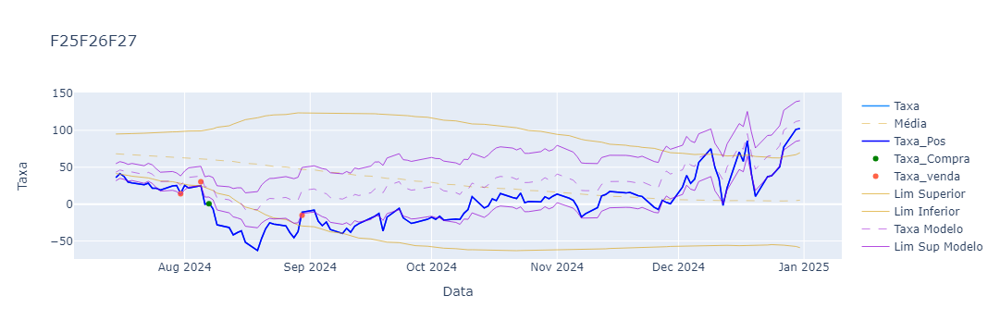

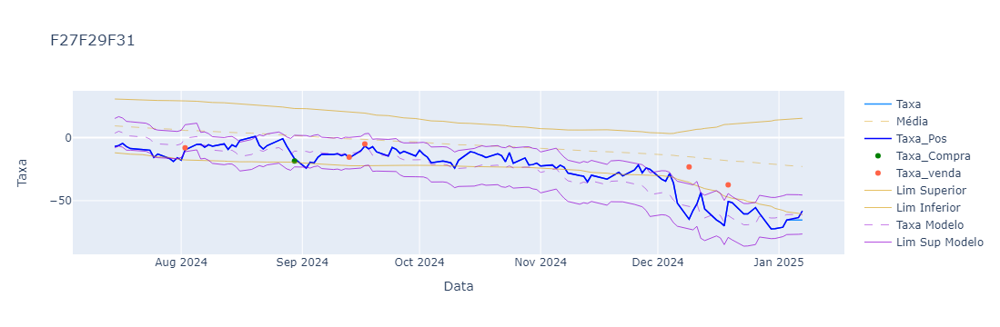

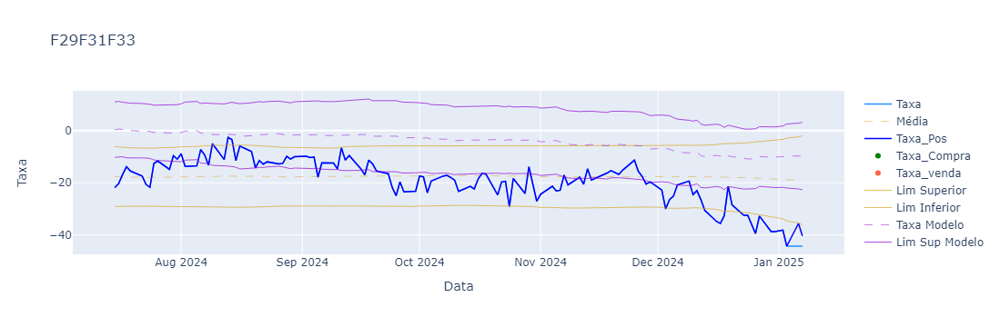

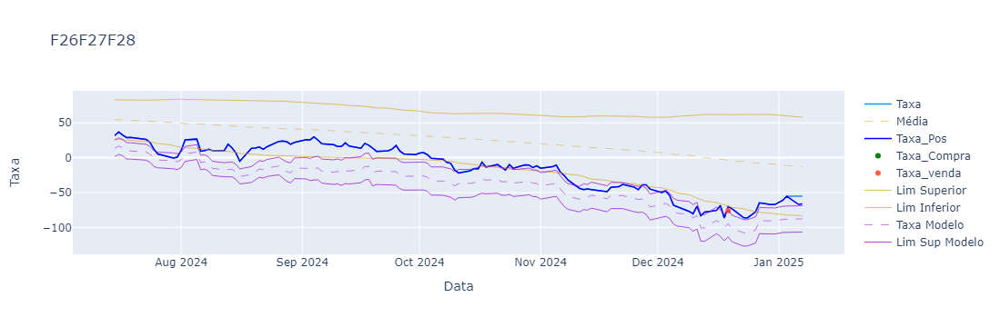

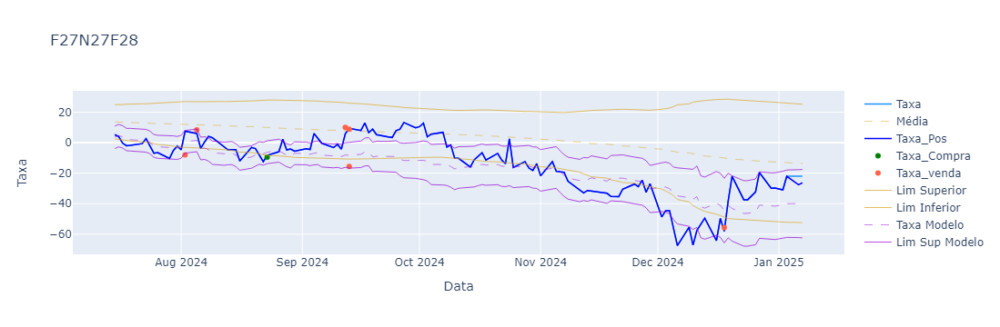

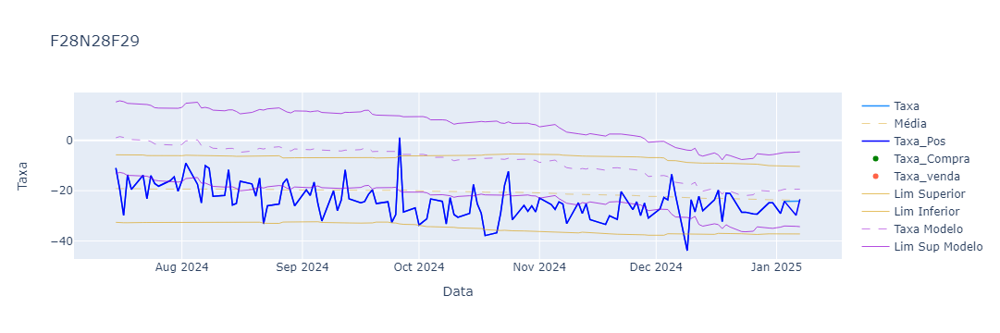

In [4]:
FLY(lista_reduzida)

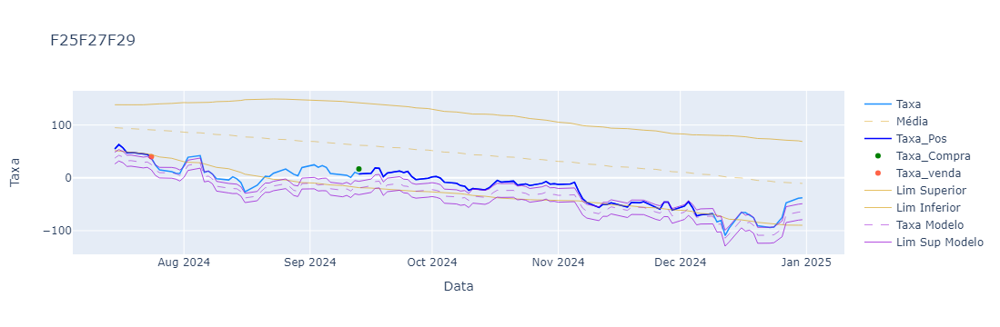

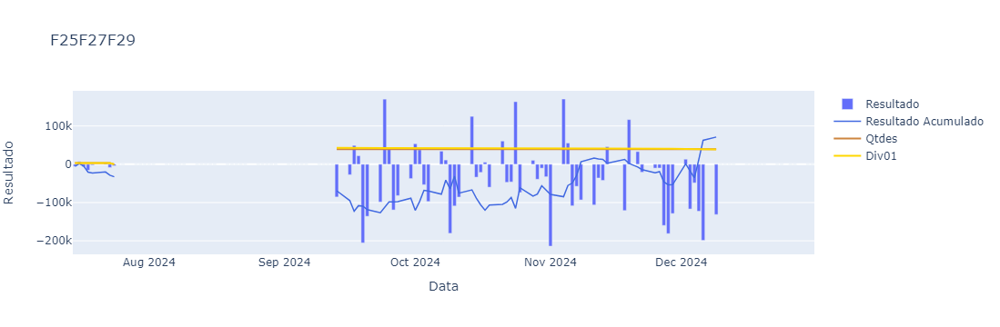

In [5]:
FLY(['F25F27F29'], graf_resultado = True)

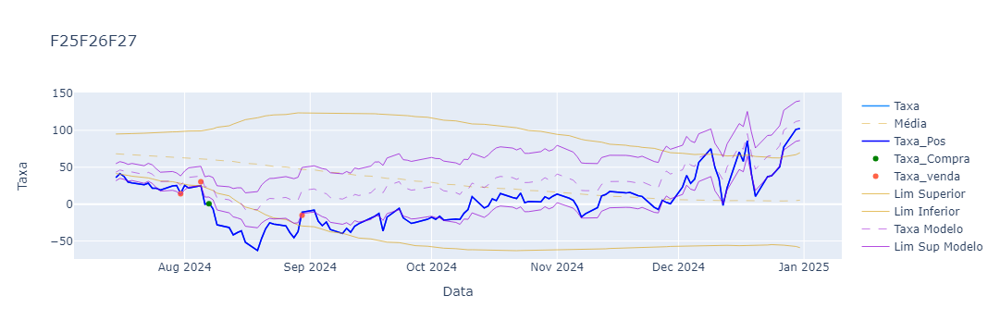

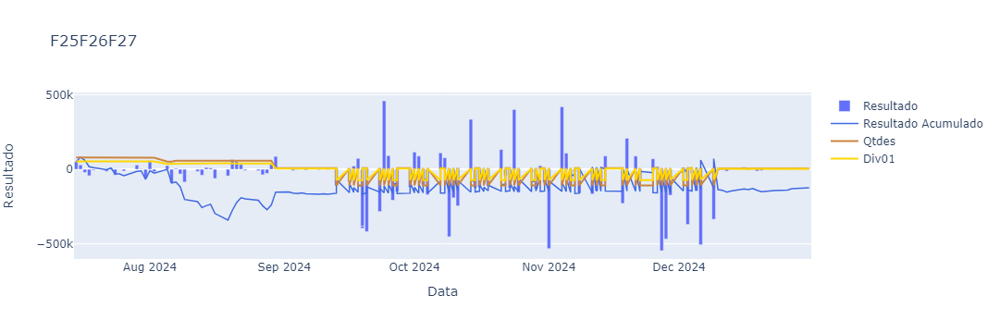

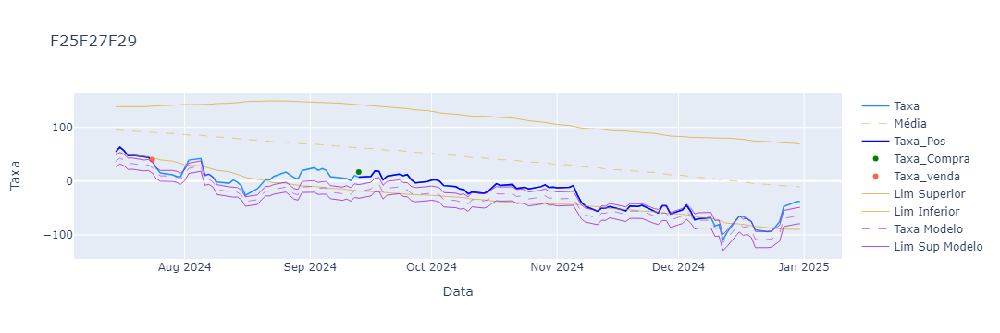

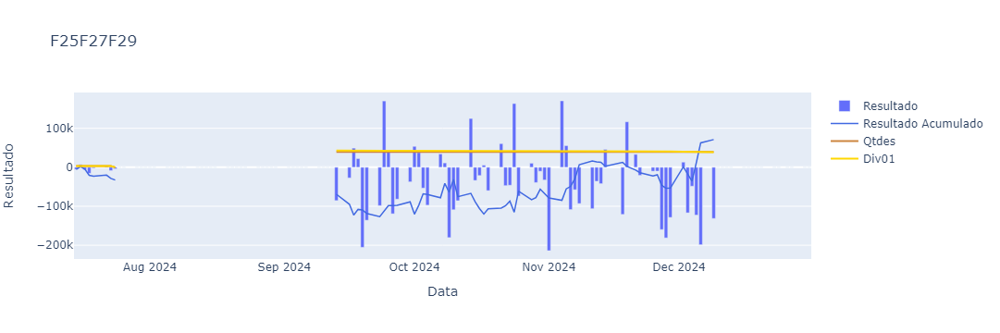

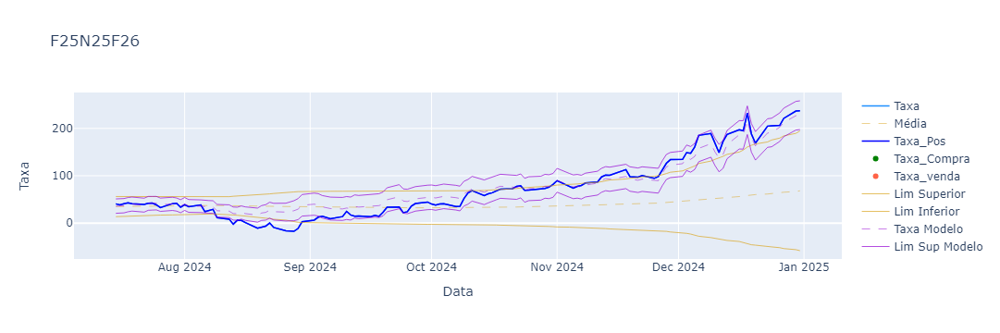

...

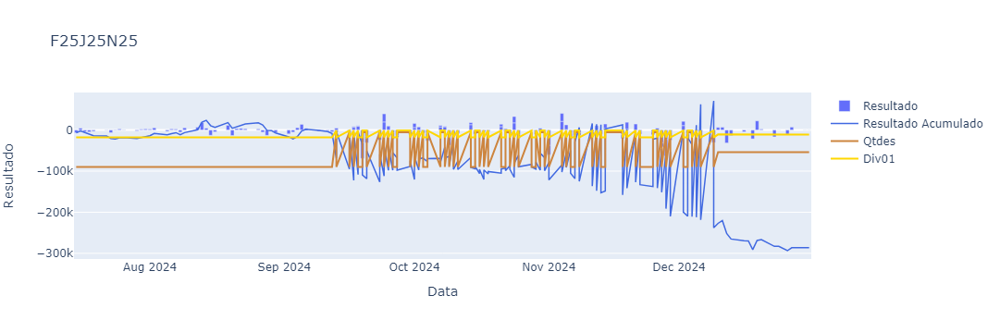

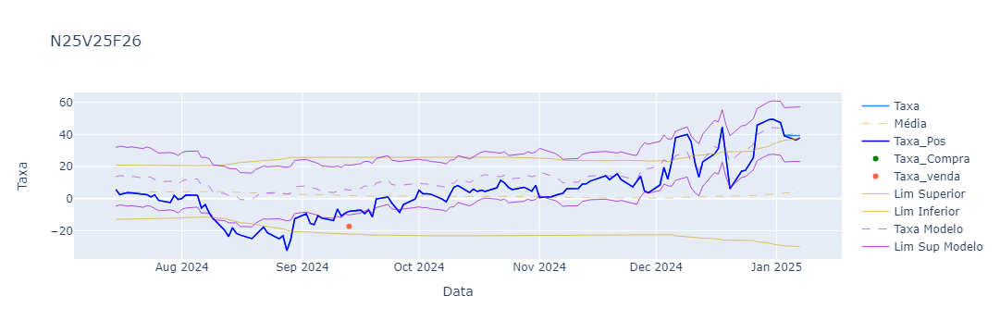

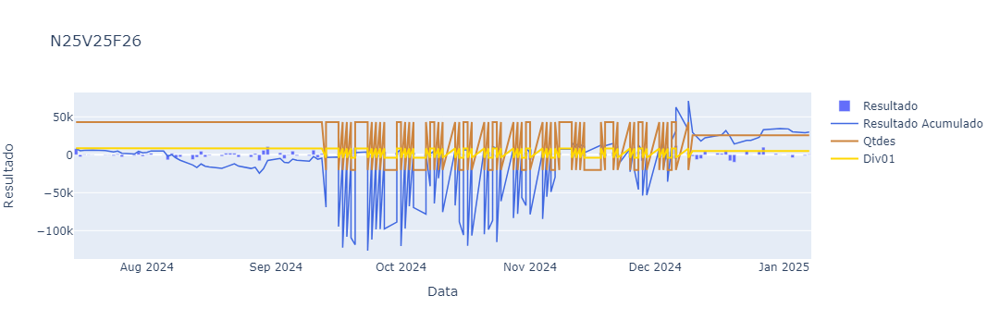

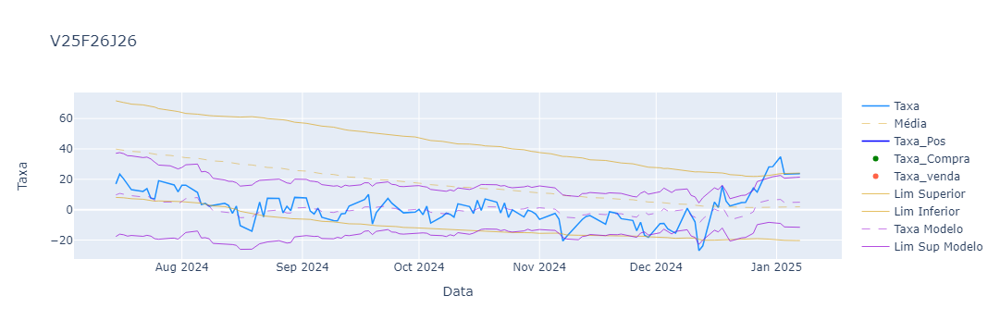

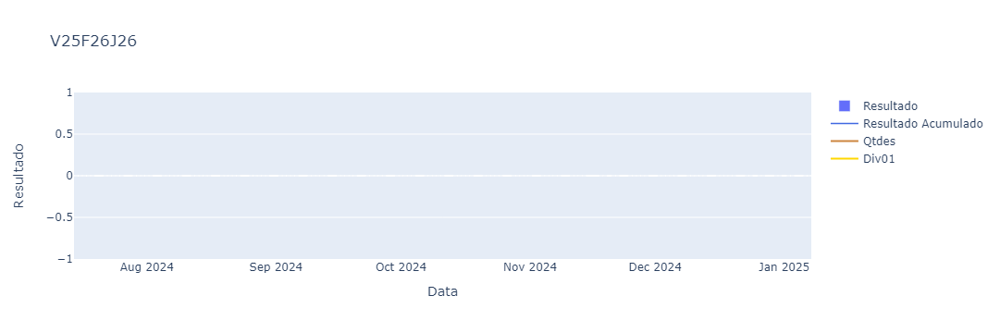

In [6]:
FLY(['F25F26F27','F25F27F29','F25N25F26','F26N26F27','F27N27F28','F28N28F29','F27F29F31','F29F31F33','N24V24F25','F25J25N25','N25V25F26','V25F26J26'], graf_resultado = True)